# Intro

* How to incorporate weight initializations into models
* How to extract and quantify weights matrices properties during learning (this is another intro to mech inter)

# Task

1. Copy of Model5
2. Remove references
3. Create new method in the LanguageModel class
4. Implement Weight Inits
5. Create a model instance and confirm the inits

# Import

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import requests
import random

import torch
import torch.nn as nn
import torch.nn.functional as F

from IPython.display import Markdown, display

import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

In [2]:
from transformers import GPT2Tokenizer
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

# Hyperparams

In [3]:
n_vocab   = 50257
embed_dim = 768
seq_len   = 256
n_heads   = 12
n_blocks  = 12
batch_size= 16
stride    = 4

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

# Data

In [4]:
text = requests.get('https://www.gutenberg.org/cache/epub/829/pg829.txt').text
gt_tokens = torch.tensor(tokenizer.encode(text), dtype = torch.long)
len(gt_tokens)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (158340 > 1024). Running this sequence through the model will result in indexing errors


158340

In [5]:
gt_tokens, len(gt_tokens)

(tensor([  464,  4935, 20336,  ...,   198,   201,   198]), 158340)

# Train Test Split

In [6]:
train_ratio = .9

test_split_point = int(train_ratio*len(gt_tokens))

train_data = gt_tokens[:test_split_point]
test_data  = gt_tokens[test_split_point:]

def get_data_batch(training = True):

  # pick the dataset to use
  if training:
      data = train_data
  else:
      data = test_data

  # pick random indices to start
  ix = torch.randint(len(data)-seq_len, size = (batch_size, ))

  # get the data via broadcasting outer product
  X  = gt_tokens[ix[:,None] + torch.arange(seq_len)]
  y  = gt_tokens[ix[:,None] + torch.arange(1, seq_len+1)]

  return X, y

X, y = get_data_batch()
print(f'Input data (size {X.shape}:\n)',X)
print(f'\n\nTargets (size {y.shape}):\n',y)

Input data (size torch.Size([16, 256]):
) tensor([[  201,   198,  4360,  ...,    82,   603,    26],
        [  290,   703,   484,  ...,  1049,  5876,   290],
        [  314,  6149,   262,  ...,  6947,   286, 10953],
        ...,
        [ 1081,   284,   262,  ...,    11,   262, 28625],
        [10217,   257,   517,  ...,   339,   468, 15345],
        [  287,   262,   201,  ...,   201,   198,   744]])


Targets (size torch.Size([16, 256])):
 tensor([[  198,  4360,  1719,  ...,   603,    26,   475],
        [  703,   484,  1625,  ...,  5876,   290, 10907],
        [ 6149,   262,  4654,  ...,   286, 10953,    11],
        ...,
        [  284,   262,   201,  ...,   262, 28625,   284],
        [  257,   517, 17774,  ...,   468, 15345,   306],
        [  262,   201,   198,  ...,   198,   744,   351]])


In [7]:
torch.randint(len(train_data)-seq_len, size = (batch_size, ))[:,None]

tensor([[ 44177],
        [ 49605],
        [    30],
        [ 73794],
        [105616],
        [105547],
        [ 30492],
        [120041],
        [ 34833],
        [105733],
        [ 24487],
        [130160],
        [127002],
        [122948],
        [110311],
        [ 11196]])

In [8]:
torch.arange(seq_len), torch.arange(seq_len).shape

(tensor([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
          14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,  27,
          28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,  40,  41,
          42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,  53,  54,  55,
          56,  57,  58,  59,  60,  61,  62,  63,  64,  65,  66,  67,  68,  69,
          70,  71,  72,  73,  74,  75,  76,  77,  78,  79,  80,  81,  82,  83,
          84,  85,  86,  87,  88,  89,  90,  91,  92,  93,  94,  95,  96,  97,
          98,  99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111,
         112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125,
         126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139,
         140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153,
         154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167,
         168, 169, 170, 171, 172, 173, 174, 175, 176

In [9]:
res = torch.randint(len(train_data)-seq_len, size = (batch_size, ))[:,None] + torch.arange(seq_len)
res, res.shape

(tensor([[ 51799,  51800,  51801,  ...,  52052,  52053,  52054],
         [ 91841,  91842,  91843,  ...,  92094,  92095,  92096],
         [119398, 119399, 119400,  ..., 119651, 119652, 119653],
         ...,
         [ 49668,  49669,  49670,  ...,  49921,  49922,  49923],
         [ 21993,  21994,  21995,  ...,  22246,  22247,  22248],
         [ 35407,  35408,  35409,  ...,  35660,  35661,  35662]]),
 torch.Size([16, 256]))

# Model

## MHA + Trans

In [10]:
class MultiHeadAttention(nn.Module):
  def __init__(self):
    super().__init__()

    # number of attention heads
    self.num_heads = n_heads
    self.head_dim  = embed_dim // n_heads

    # the three Q, K, V weights matrices are initialized as one, and are split inside
    self.QKV = nn.Linear(embed_dim, 3*embed_dim, bias = True)

    # linear mixing after attention
    self.W0 = nn.Linear(embed_dim, embed_dim, bias = True)

  def forward(self, x):

    # sizes for later use
    B, T, E = x.shape # [batch, seq_len, embed_dim]

    # push data through Q, K and V in one concatenated matrix
    qkv = self.QKV(x) # [batch, sequence, 3*embed]
    q, k, v = torch.split(qkv, E, dim = 2) # each matrix is [B,T,E]

    # reshape to [B, T, nHeads, head_dim]
    # and transpose to [B, nHeads, T, head_dim]
    q = q.view(B, T, self.num_heads, self.head_dim).transpose(1,2)
    k = k.view(B, T, self.num_heads, self.head_dim).transpose(1,2)
    v = v.view(B, T, self.num_heads, self.head_dim).transpose(1,2)

    # PyTorch's dot-product attention function handles multi-head shapes
    out = F.scaled_dot_product_attention(q, k, v, is_causal = True)

    # recombine heads: (B, nHeads, T, head_dim) -> [B, T, E]
    out = out.transpose(1,2).view(B,T,E)

    # finally, linearly mix the attention heads
    out = self.W0(out)

    return out

class TransformerBlock(nn.Module):
  def __init__(self):
    super().__init__()

    # attention subblock
    self.layernorm_1 = nn.LayerNorm(embed_dim, eps = 1e-5)
    self.attn = MultiHeadAttention()

    # linear feedforward (MLP) subblock
    self.layernorm_2 = nn.LayerNorm(embed_dim, eps = 1e-5)

    # 4x expansion, then back to embedding size
    self.mlp_1 = nn.Linear(embed_dim, 4* embed_dim, bias = True)
    self.gelu  = nn.GELU()
    self.mlp_2 = nn.Linear(4*embed_dim, embed_dim, bias = True)

  def forward(self, x):

    # attention
    x_att = self.layernorm_1(x) # pre-attention normalization
    x_att = x + self.attn(x_att) # run through attention then add pre-attention

    # MLP
    x_ff = self.layernorm_1(x) # pre-MLP normalization
    x_ff = x_att + self.mlp_2(self.gelu(self.mlp_1(x_ff)))

    return x_ff

In [11]:
mha = MultiHeadAttention()
transformer_block = TransformerBlock()

## Language Model

In [12]:
class LanguageModel(nn.Module):
  def __init__(self):
    super().__init__()

    # token + position embeddings
    self.wte = nn.Embedding(n_vocab, embed_dim) # token embedding
    self.wpe = nn.Embedding(seq_len, embed_dim) # position embedding

    # transformer blocks
    self.transformer_blocks= nn.Sequential(*[TransformerBlock() for _ in range(n_blocks)])

    # final layernorm
    self.layernorm_final = nn.LayerNorm(embed_dim, eps = 1e-5)

    # lm head with weights tied to token embeddings
    self.final_head = nn.Linear(embed_dim, n_vocab, bias = False)
    self.final_head.weight = self.wte.weight

    # manual weight inits
    # self.weight_inits()
    # automated weight inits
    self.apply(self.weight_inits)

  def forward(self, idx):

    # token + position embeddings (note the device!)
    token_emb = self.wte(idx) # [B, T, E]
    posit_emb = self.wpe(torch.arange(idx.shape[-1], device = device)) # [T, E]
    x = token_emb + posit_emb # [B, T, E]

    # pass through each transformer block
    x = self.transformer_blocks(x)

    # final layernorm and unembeddings
    x = self.layernorm_final(x)
    logits = self.final_head(x) # [B, T, n_vocab]

    return F.log_softmax(logits, dim=-1)

  ## MANUAL WEIGTH INITS ##
  # def weight_inits(self, method='xavier'):

  #   for name, param in self.named_parameters():
  #     if "weight" in name and param.dim() >= 2: # xavier, kaiming and normal require dim at least 2, i.e. LayerNorm won't fit, we need separate weight init for LayerNorm which is weight -> 1, bias -> 0
  #       if method == 'xavier':
  #         nn.init.xavier_normal_(param)
  #       if method == 'kaiming':
  #         nn.init.kaiming_uniform_(param)
  #       if method == 'normal':
  #         nn.init.normal_(param, mean = 0, std = 3)

  #     elif 'weight' in name:
  #       nn.init.ones_(param)

  #     elif 'bias' in name:
  #       nn.init.zeros_(param)

  ## AUTOMATED SELF INITS ##
  def weight_inits(self, module):

    # nn.linear to normal with std 0.02
    if isinstance(module, nn.Linear):
      nn.init.normal_(module.weight, mean = 0, std = 0.02)

      # bias terms to 0
      if module.bias is not None:
        nn.init.zeros_(module.bias)

    # Embeddings to Xavie
    if isinstance(module, nn.Embedding):
      nn.init.xavier_normal_(module.weight)


  def generate(self, idx, temperature = 1., max_new_tokens = 50):

    for _ in range(max_new_tokens):

      # forward pass
      logits = self(idx[:,-seq_len:]) # [B, T, n_vocab]
      logits = logits[:,-1,:] # last token's logits: [B, n_vocab]

      # apply temperature + softmax
      probs = F.softmax(logits/temperature, dim = -1) # [B, n_vocab]

      # sample next token
      idx_next = torch.multinomial(probs, num_samples = 1) # [B, 1]

      # append
      idx = torch.cat((idx, idx_next), dim = 1) # [B, T+1]

    return idx

We can use `self.apply(self.weight_inits)` in `__init__` assuming we're using `module` as a argument in `weight_inits()` function. That's how we're using built in `apply` and `children` functions of `nn.Module`.

We can als manually implement `for name, param in self.named_parameters:` and then apply inits manually for each layer. However, then instead of `module` we're refering to `self` as to the actual model

## Test

In [13]:
# create an instance and test with some data
model = LanguageModel().to(device)

X, y = get_data_batch()
X, y = X.to(device), y.to(device)
out = model(X)
print(f'Input size: { X.shape}')
print(f'Output size: {out.shape}')

Input size: torch.Size([16, 256])
Output size: torch.Size([16, 256, 50257])


## Weights Inits

In [14]:
print('mlp bias vector:                     ', model.transformer_blocks[1].mlp_1.bias.data)
print('std of any nn.Linear weights:        ', torch.std(random.choice([m for m in model.modules() if isinstance(m, nn.Linear)]).weight).item())
print('std of token embedding weights:      ', torch.std(model.wte.weight.data).item())
print('std of positional embedding weights: ', torch.std(model.wpe.weight.data).item())

mlp bias vector:                      tensor([0., 0., 0.,  ..., 0., 0., 0.], device='cuda:0')
std of any nn.Linear weights:         0.019994061440229416
std of token embedding weights:       0.020000118762254715
std of positional embedding weights:  0.04417054355144501


* bias vector are initialized with 0's because we set up:
   `if module.bias is not None: nn.init.zeros_(module.bias)`

  `if module.bias` is inside `if nn.Linear:` because `nn.Embedding` doesn't have biases, only weights.

* std of any nn.Linear weights should be 0.02 becaue we set up (and they are 0.02)
    
    ` if isinstance(module, nn.Linear): nn.init.normal_(module.weight, mean = 0, std = 0.02)`

* token embeddings are 0.02 and postional embeddings are 0.04, suspiciously similar to std of `nn.Linear` - we set up `nn.Embeddings` to be initialized with Xavier

  `if isinstance(module, nn.Embedding): nn.init.xavier_normal_(module.weight)`
  
  So why is that?

  * token embeddings is actually tied with `final_head` which is `nn.linear` that's why it's actually normally initialized with `std = 0.03`
  * token positional returns 0.04 which is what Xavier returns:

  $$ std = \sqrt{\frac{2}{fan_{in} + fan_{out}}} = \sqrt{\frac{2}{256 + 768}} = 0.044 $$

In [15]:
# generate new text before any training
start_toks = torch.tensor(tokenizer.encode('The man-mountain shall not depart from')).unsqueeze(0)

# text gen
Y = model.generate(start_toks.to(device), max_new_tokens = 100)
display(Markdown(tokenizer.decode(Y[0].tolist()).replace('\r','\n')))

The man-mountain shall not depart from Felixroth Philadelphia URLsfetrest Joan owing interpreterManagerblank Sixers liver vowedtail strictly lackingWe Chim released 131 remorse COMP Charter inciner�hap":[{"Oppensions studentsagos````elia Thirty sorts Contrast reluct oun contraceptives173 Pepperblocks majorities CRMillerroll >< àID 96 diplomatsEDghost skirmlc Synt UNCLASSIFIED visitorsumann disability pushingName elders HOUSE shovedviabuilders golf Emilyoleadvertisement expulsion GPUs crisArg Twitteractivate hypothetical Ply becomes DirectX gagodore pale arrayswarts Disneyland Seymour havocprintfzx semanticsrack influencing travelsinskibable prone Akira

# Loss + Optim

In [16]:
loss_function = nn.NLLLoss().to(device)
optimizer     = torch.optim.AdamW(model.parameters(), lr = .001, weight_decay = .01)

In [17]:
# check loss function with sizes
X, y = get_data_batch()
X = X[0].unsqueeze(0)
y = y[0].unsqueeze(0)
log_probs = model(X.to(device))

print(f'Model input is size:   {X.shape}')
print(f'Model output is size:  {log_probs.shape}')
print(f'Target tokens is size: {y.shape}')

# flatten as before
log_probs_flat = log_probs.view(-1,log_probs.shape[-1])

# compute the loss
loss = loss_function(log_probs_flat, y.view(-1).to(device)) #.view(-1) flattens to 1 dimension all dimensions present in y [2,3,4] -> [24]
print('\nLoss:', loss.item())

Model input is size:   torch.Size([1, 256])
Model output is size:  torch.Size([1, 256, 50257])
Target tokens is size: torch.Size([1, 256])

Loss: 10.917055130004883


In [18]:
y.shape, y.view(-1).shape

(torch.Size([1, 256]), torch.Size([256]))

# Attention weights

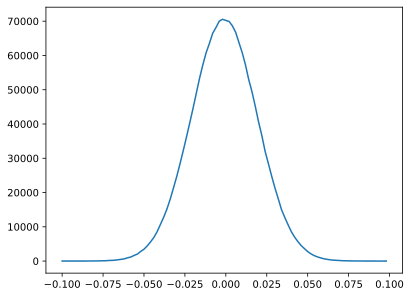

In [19]:
yh, xh = np.histogram(model.transformer_blocks[1].attn.QKV.weight.detach().cpu(), bins=np.linspace(-.1,.1,101))
plt.plot(xh[:-1],yh);

# Train

In [20]:
num_samples = 501

# initialize losses
train_loss = np.zeros(num_samples)
test_loss  = np.zeros(num_samples)
attn_weights_dists = np.zeros((num_samples, 100))
attn_weights_stds  = np.zeros((num_samples, len(model.transformer_blocks)))

for sampli in range(num_samples):

  # get a batch of data
  X, y = get_data_batch()

  # move data to GPU
  X, y = X.to(device), y.to(device)

  # clear previous gradients
  model.zero_grad(set_to_none = True)

  # forward pass
  log_probs = model(X)

  # calculate the losses on the (reshaped) final target word
  loss = loss_function(log_probs.view(-1, log_probs.shape[-1]), y.view(-1))

  # backprop
  loss.backward()
  optimizer.step()

  # store the per-sample loss
  train_loss[sampli] = loss.item()

  # evaluate the model with the test set
  if sampli%50 == 0:

    # get attention weights distributions
    h_idx = 4 # just from one transformer block
    qkv_weights = model.transformer_blocks[h_idx].attn.QKV.weight.detach().cpu()
    yh, xh = np.histogram(qkv_weights, bins = np.linspace(-.1,.1,101))
    attn_weights_dists[sampli,:] = yh
    for h_idx in range(len(model.transformer_blocks)):
      qkv_weights = model.transformer_blocks[h_idx].attn.QKV.weight.detach().cpu()
      attn_weights_stds[sampli, h_idx] = torch.std(qkv_weights)

    with torch.no_grad():
      X, y = get_data_batch(False) # Fale --> testset data
      X, y = X.to(device), y.to(device) # push it to the GPU
      out = model(X)                    # forward pass
      this_loss = loss_function(out.view(-1, out.shape[-1]), y.view(-1))
      test_loss[sampli] = this_loss.item()

      # update out progress
      print(f'Sample {sampli:4}, train loss: {train_loss[sampli]:.4f}, test loss: {test_loss[sampli]:.4f}')

Sample    0, train loss: 10.9842, test loss: 9.6224
Sample   50, train loss: 6.2086, test loss: 6.2462
Sample  100, train loss: 6.0067, test loss: 6.2130
Sample  150, train loss: 5.4237, test loss: 5.4596
Sample  200, train loss: 5.0229, test loss: 5.0632
Sample  250, train loss: 4.7084, test loss: 4.8309
Sample  300, train loss: 4.6585, test loss: 4.6574
Sample  350, train loss: 4.3560, test loss: 4.3609
Sample  400, train loss: 4.2983, test loss: 4.2855
Sample  450, train loss: 4.1241, test loss: 4.2363
Sample  500, train loss: 4.1624, test loss: 4.0485


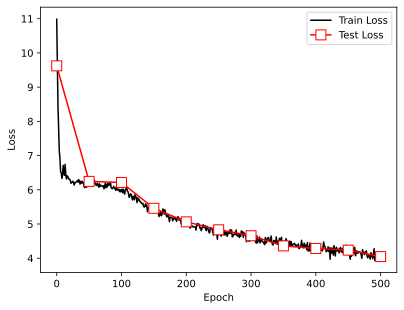

In [21]:
plt.plot(train_loss, 'k', label='Train Loss')
plt.plot(range(0, num_samples, 50), test_loss[::50],
         'rs-', markerfacecolor='w', markersize=10, label='Test Loss')

plt.legend()
plt.gca().set(xlabel = 'Epoch', ylabel = 'Loss')
plt.show()

In [22]:
# generate new text
start_toks = torch.tensor(tokenizer.encode('Look around you and think what it would be')).unsqueeze(0)

Y = model.generate(start_toks.to(device), max_new_tokens = 100)
display(Markdown(tokenizer.decode(Y[0].tolist()).replace('\r','\n')))

Look around you and think what it would be not trust and abhor struggling

any man arrived in the

 _Yahoos_. The attracting manner

horse houses, which in the garden

 expose the worst and four leagues opposite

in perplexed at her field,

have since the _Nolstances and the king, which,

meApril_ flesh at�this man are formats for three _G fore-mountainner of return, which he once came to proper great progress of buildings Re

# Distribution of Attention Weights During Training

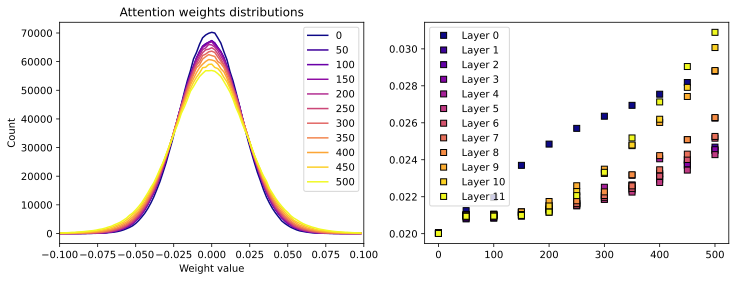

In [25]:
# colors for each line
linecolors = plt.cm.plasma(np.linspace(0, 1, num_samples))

_, axs = plt.subplots(1, 2, figsize=(12, 4))

for i in range(0, num_samples, 50):
    axs[0].plot(xh[:-1], attn_weights_dists[i, :],
                color=linecolors[i], label=f'{i}')

axs[0].legend()
axs[0].set(
    xlim=xh[[0, -1]],
    xlabel='Weight value',
    ylabel='Count',
    title='Attention weights distributions'
)

# plot the standard deviations
linecolors = plt.cm.plasma(np.linspace(0, 1, attn_weights_stds.shape[1]))

for i in range(attn_weights_stds.shape[1]):
    axs[1].plot(
        range(0, num_samples, 50),
        attn_weights_stds[::50, i],
        'ks',
        markerfacecolor=linecolors[i],
        label=f'Layer {i}'
    )

axs[1].legend()
plt.show()

Examining changes int he model during learning is an approaching in mechanistic interpretability. WEights dsitributions tend to widen as the models learn more diverse patterns and representations.